# 4.2 · Supply, emissions, inflation and burn
### Module 4 · DeFi II · Topic 1 — a data lab

We measure two **supply-dynamics** quantities, from the framework
(Domenicale, Avanzo & Schifanella, 2026) on real tokens:

- **Supply inflation (oversupply).** From Fisher's equation of exchange $MV=PQ$,
  the supply-inflation rate is $\pi=\dot M/M+\dot V/V-\dot Q/Q$; a token is *structurally oversupplied*
  when $\dfrac{\Delta(MV)}{MV}>\dfrac{\Delta Q}{Q}$. The consistent supply at a given velocity is
  $M_{\text{consistent}}=PQ/V$.
- **Burn/emission balance.** Net supply change is $\dot M=E(t)-B(t)$; sustainability
  (Sidrauski) requires $E-B\le g\,M$. The **burn coverage ratio** $\rho=B/E$ must satisfy $\rho\ge 1$
  under zero growth; $\rho<1$ is structural long-run inflation.

**Good/bad cases:** ETH (EIP-1559 burn → near-zero net issuance) and BNB (capped + auto-burn) vs
CRV (high emission, no token burn).

**Data (all free, no key):** CoinGecko (`/coins`, `/market_chart`), ultrasound.money (ETH net issuance),
DeFiLlama datasets (emission schedule).

## Setup

In [1]:
%matplotlib inline
import requests, json, os, time, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

CACHE = "data"; os.makedirs(CACHE, exist_ok=True)

def _cache(key):
    return os.path.join(CACHE, key + ".json")

def cget(url, params=None, key=None, pause=2.5):
    """GET JSON with a local cache, so the notebook re-runs offline without hitting rate limits."""
    if key and os.path.exists(_cache(key)):
        return json.load(open(_cache(key)))
    for _ in range(3):
        try:
            r = requests.get(url, params=params, timeout=40)
            if r.status_code == 200:
                data = r.json()
                if key:
                    json.dump(data, open(_cache(key), "w"))
                time.sleep(pause)
                return data
        except requests.RequestException:
            pass
        time.sleep(1.5)
    raise RuntimeError(f"failed: {url}")

# --- API endpoints (single source of truth) ---
CG = "https://api.coingecko.com/api/v3"     # market data: supply, price, volume, market cap
US = "https://ultrasound.money/api/v2"      # ETH issuance and EIP-1559 burn
DL = "https://defillama-datasets.llama.fi"  # emission / unlock schedules

TOKENS = {"ethereum": "ETH", "binancecoin": "BNB", "curve-dao-token": "CRV"}

## 1 · Supply and the dilution overhang
Circulating vs max supply tells us how much future emission is already scheduled.

In [2]:
rows = []
for cid, sym in TOKENS.items():
    d = cget(f"{CG}/coins/{cid}", params={"localization":"false","tickers":"false",
             "market_data":"true","community_data":"false","developer_data":"false"}, key=f"coin_{cid}")
    m = d["market_data"]
    circ, mx = m["circulating_supply"], m.get("max_supply")
    overhang = (1 - circ/mx) if mx else float("nan")
    rows.append(dict(token=sym, price_usd=round(m["current_price"]["usd"],4),
                     circulating=round(circ), max_supply=(round(mx) if mx else None),
                     dilution_overhang=(round(100*overhang,1) if mx else None),
                     mcap_usd=round(m["market_cap"]["usd"]), vol24h_usd=round(m["total_volume"]["usd"])))
supply = pd.DataFrame(rows); supply

,token,price_usd,circulating,max_supply,dilution_overhang,mcap_usd,vol24h_usd
0,ETH,1883.9100,120681993,NaN,NaN,227329692699,6902821917
1,BNB,610.8100,133164088,2.000000e+08,33.4,81321123402,514630342
2,CRV,0.2553,1547373226,3.030303e+09,48.9,395015087,59935574


## 2 · Annual inflation from supply history
We reconstruct circulating supply as `market_cap / price` over the last year (CoinGecko `market_chart`), then take the change.

In [3]:
def annual_inflation(cid):
    d = cget(f"{CG}/coins/{cid}/market_chart",
             params={"vs_currency":"usd","days":"365","interval":"daily"}, key=f"chart_{cid}")
    mc, pr = d["market_caps"], d["prices"]
    s0 = mc[0][1]/pr[0][1]; s1 = mc[-1][1]/pr[-1][1]
    return 100*(s1-s0)/s0
infl = {sym: round(annual_inflation(cid),2) for cid, sym in TOKENS.items()}
print("Annual supply inflation (market_chart, supply = mcap/price):")
for s,v in infl.items(): print(f"  {s}: {v:+.2f}% / yr")

Annual supply inflation (market_chart, supply = mcap/price):
  ETH: -0.21% / yr
  BNB: -4.43% / yr
  CRV: +11.52% / yr


## 3 · ETH net issuance and the EIP-1559 burn
For ETH the precise figure comes from `ultrasound.money`: total supply over time. Since the Merge, the fee burn has held net issuance near zero.

In [4]:
us = cget(f"{US}/fees/supply-over-time", key="eth_supply_over_time", pause=0)

def window_rate(series, key):
    """Annualised net-supply change over a named window of the ultrasound supply series."""
    a, b = series[key][0], series[key][-1]
    days = (pd.to_datetime(b["timestamp"]) - pd.to_datetime(a["timestamp"])).days
    chg  = b["supply"] - a["supply"]
    ann  = chg / days * 365
    return chg, ann, ann / b["supply"] * 100, days

for k, lab in [("since_merge", "since Merge"), ("d30", "last 30 days")]:
    chg, ann, rate, days = window_rate(us, k)
    print(f"  {lab:14} ({days:>4} d)  \u0394supply={chg:+,.0f} ETH  ->  annualized {ann:+,.0f} ETH/yr = {rate:+.2f}%/yr")

eth_infl = window_rate(us, "since_merge")[2]
print(f"\nETH structural inflation ~ {eth_infl:+.2f}%/yr (vs ~4%/yr under pre-Merge proof-of-work).")

  since Merge    (1428 d)  Δsupply=+1,427,649 ETH  ->  annualized +364,910 ETH/yr = +0.30%/yr
  last 30 days   (  30 d)  Δsupply=+85,721 ETH  ->  annualized +1,042,937 ETH/yr = +0.86%/yr

ETH structural inflation ~ +0.30%/yr (vs ~4%/yr under pre-Merge proof-of-work).


## 4 · Emission schedule as the oversupply source
CRV's supply grows on a scheduled emission curve (DeFiLlama datasets). A rising, uncorrected schedule is the oversupply driver.

CRV emission/unlock categories: ['community reserve', 'community', 'employees', 'early users', 'team and investors']


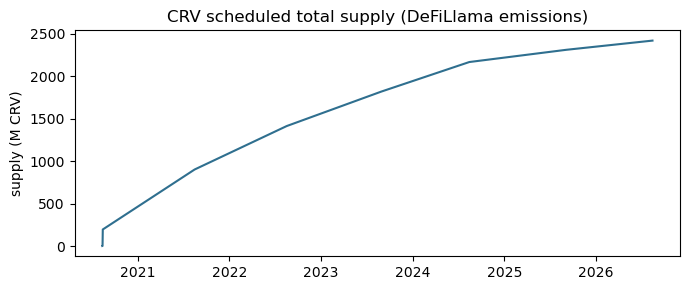

In [5]:
try:
    em = cget(f"{DL}/emissions/curve", key="emissions_curve", pause=0)
    cats = em["data"]
    print("CRV emission/unlock categories:", [c["label"] for c in cats][:8])

    # cumulative unlocked supply over time, summed across all categories
    unlocked = collections.defaultdict(float)
    for cat in cats:
        for pt in cat["data"]:
            unlocked[pt["timestamp"]] += pt.get("unlocked", 0) or 0

    ts = sorted(unlocked)
    xs = [pd.to_datetime(t, unit="s") for t in ts]
    ys = np.array([unlocked[t] for t in ts]) / 1e6

    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(xs, ys, color="#2f6f8f")
    ax.set_title("CRV scheduled total supply (DeFiLlama emissions)")
    ax.set_ylabel("supply (M CRV)")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("emission schedule unavailable:", e)

## 5 · Burn coverage and net issuance, read together
$\rho=B/E$: ETH's burn is *demand-driven* (tied to gas), BNB runs a scheduled auto-burn, CRV has **no token burn** ($\rho=0$).

In [6]:
# Exact ETH burn coverage  rho = B/E  (ultrasound.money burn-sums + net supply)
bs = cget(f"{US}/fees/burn-sums", key="eth_burn_sums", pause=0)
B_sm  = bs["since_merge"]["sum"]["eth"]                                  # ETH burned since the Merge
dM_sm = us["since_merge"][-1]["supply"] - us["since_merge"][0]["supply"] # net supply change
E_sm  = dM_sm + B_sm                                                     # issuance = net + burn
rho_eth = B_sm / E_sm
print(f"ETH since the Merge:  burn B = {B_sm:,.0f} ETH  |  issuance E = {E_sm:,.0f} ETH  |  rho = B/E = {rho_eth:.3f}")
print(f"  ETH's burn covers {rho_eth*100:.0f}% of issuance; rho < 1, so net supply still grows ({eth_infl:+.2f}%/yr).\n")

burn = pd.DataFrame([
    dict(token="ETH", burn="demand-driven (EIP-1559 gas)", rho=f"{rho_eth:.2f}",   net_issuance_pct=round(eth_infl, 2)),
    dict(token="BNB", burn="scheduled auto-burn to 100M",  rho="n/a (no issuance)", net_issuance_pct=infl["BNB"]),
    dict(token="CRV", burn="none",                         rho="0",                 net_issuance_pct=infl["CRV"]),
])
burn

ETH since the Merge:  burn B = 2,013,883 ETH  |  issuance E = 3,441,532 ETH  |  rho = B/E = 0.585
  ETH's burn covers 59% of issuance; rho < 1, so net supply still grows (+0.30%/yr).



,token,burn,rho,net_issuance_pct
0,ETH,demand-driven (EIP-1559 gas),0.59,0.30
1,BNB,scheduled auto-burn to 100M,n/a (no issuance),-4.43
2,CRV,none,0,11.52


## 6 · Comparison — good vs bad on the supply side

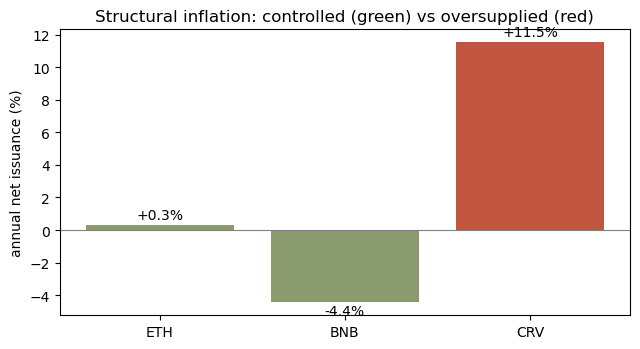

In [7]:
order = ["ETH","BNB","CRV"]
vals = [eth_infl, infl["BNB"], infl["CRV"]]
fig, ax = plt.subplots(figsize=(6.5,3.6))
cols = ["#8a9b6e" if v<=2 else "#c05640" for v in vals]
ax.bar(order, vals, color=cols)
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylabel("annual net issuance (%)"); ax.set_title("Structural inflation: controlled (green) vs oversupplied (red)")
for i,v in enumerate(vals): ax.text(i, v+(0.4 if v>=0 else -0.8), f"{v:+.1f}%", ha="center")
plt.tight_layout(); plt.show()

## 7 · Interpretation
- **ETH & BNB — supply-stable:** net issuance near zero or negative, with a **demand-linked** corrective (gas burn) or a scheduled burn. supply inflation and burn balance both healthy.
- **CRV — structurally oversupplied:** ~double-digit annual emission, a large dilution overhang, and **no token burn** ($\rho=0$) — high emission and no burn reinforcing. Its mitigant is *locking* (veCRV), a velocity-side fix examined in 4.3.
- **Read together:** supply stability needs *both* controlled net issuance *and* a demand-linked corrective; neither alone suffices.

## Caveats
- Supply reconstructed as `mcap/price` carries small error; for ETH the precise figure is the ultrasound.money supply series.
- Uncapped tokens have no `max_supply` (dilution overhang undefined); treasury/off-chain emissions may not appear in circulating supply.
- A *rule-driven* burn independent of usage creates no real link to value (framework §3.3).

## Your task
1. Add two tokens (one capped, one uncapped high-emission), compute annual inflation and dilution overhang, and classify each on the inflation and burn-coverage axes.
2. For one token, compute $M_{\text{consistent}}=PQ/V$ using turnover from notebook 4.3 as $V$, and compare to actual supply.
3. Which is more informative for sustainability — the *level* of supply or its *rate of change*? Justify with your numbers.